In [21]:
import pandas as pd

df = pd.read_csv('../data/raw/creditcard.csv')
print("Dataset Shape:" , df.shape)
print("-" * 50)

print("Coloumn names:\n " , df.columns.tolist())
print("-" * 50)


print("First 5 Rows:")
df.head()

class_counts = df['Class'].value_counts()
normal_count = class_counts.get(0,0)
fraud_count = class_counts.get(1,0)

total_rows = len(df)
fraud_percentage = (fraud_count / total_rows) * 100


print(f"Normal Transactions (Class 0): {normal_count:,}")
print(f"Fraud Transactions (Class 1):  {fraud_count:,}")
print(f"Fraud Percentage: {fraud_percentage:.4f}%")



Dataset Shape: (284807, 31)
--------------------------------------------------
Coloumn names:
  ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
--------------------------------------------------
First 5 Rows:
Normal Transactions (Class 0): 284,315
Fraud Transactions (Class 1):  492
Fraud Percentage: 0.1727%


In [22]:
missing_values = df.isnull().sum()
total_missing  = missing_values.sum()

duplicate_count = df.duplicated().sum()

data_types = df.dtypes

print("Data Quality Check Results")
print(f"Total Missing Values: {total_missing}")
if total_missing > 0:
    print(missing_values[missing_values > 0])
else:
    print("-> No missing values found in any column.")

print(f"\nDuplicate Rows Found: {duplicate_count}")
if duplicate_count > 0:
    print("-> Needed to drop these duplicates before training your model.")
else:
    print("-> No duplicate rows found.")

print("\nData Types Summary:")
print(data_types.value_counts())

Data Quality Check Results
Total Missing Values: 0
-> No missing values found in any column.

Duplicate Rows Found: 1081
-> Needed to drop these duplicates before training your model.

Data Types Summary:
float64    30
int64       1
Name: count, dtype: int64


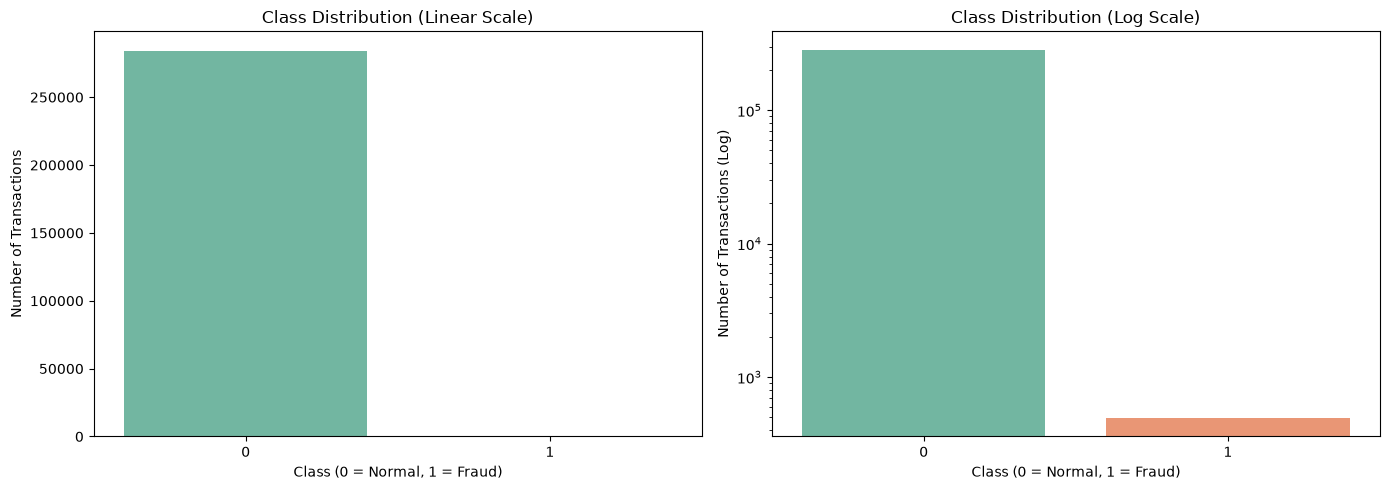

--- Top Negative Correlations with Class ---
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64

--- Top Positive Correlations with Class ---
V11    0.154876
V4     0.133447
V2     0.091289
V21    0.040413
V19    0.034783
Name: Class, dtype: float64


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Linear Scale (Standard)
sns.countplot(x='Class', data=df, ax=axes[0], hue = 'Class' ,palette='Set2', legend = False)
axes[0].set_title('Class Distribution (Linear Scale)')
axes[0].set_xlabel('Class (0 = Normal, 1 = Fraud)')
axes[0].set_ylabel('Number of Transactions')

# Plot 2: Log Scale
sns.countplot(x='Class', data=df, ax=axes[1], palette='Set2' , hue= 'Class', legend =False)
axes[1].set_yscale('log')
axes[1].set_title('Class Distribution (Log Scale)')
axes[1].set_xlabel('Class (0 = Normal, 1 = Fraud)')
axes[1].set_ylabel('Number of Transactions (Log)')

plt.tight_layout()
plt.show()

# Compute correlation of all features with the target 'Class'
correlations = df.corr()['Class'].sort_values()

print("--- Top Negative Correlations with Class ---")
print(correlations.head(5))

print("\n--- Top Positive Correlations with Class ---")
print(correlations.tail(6).iloc[:-1][::-1]) # Exclude Class correlating with itself


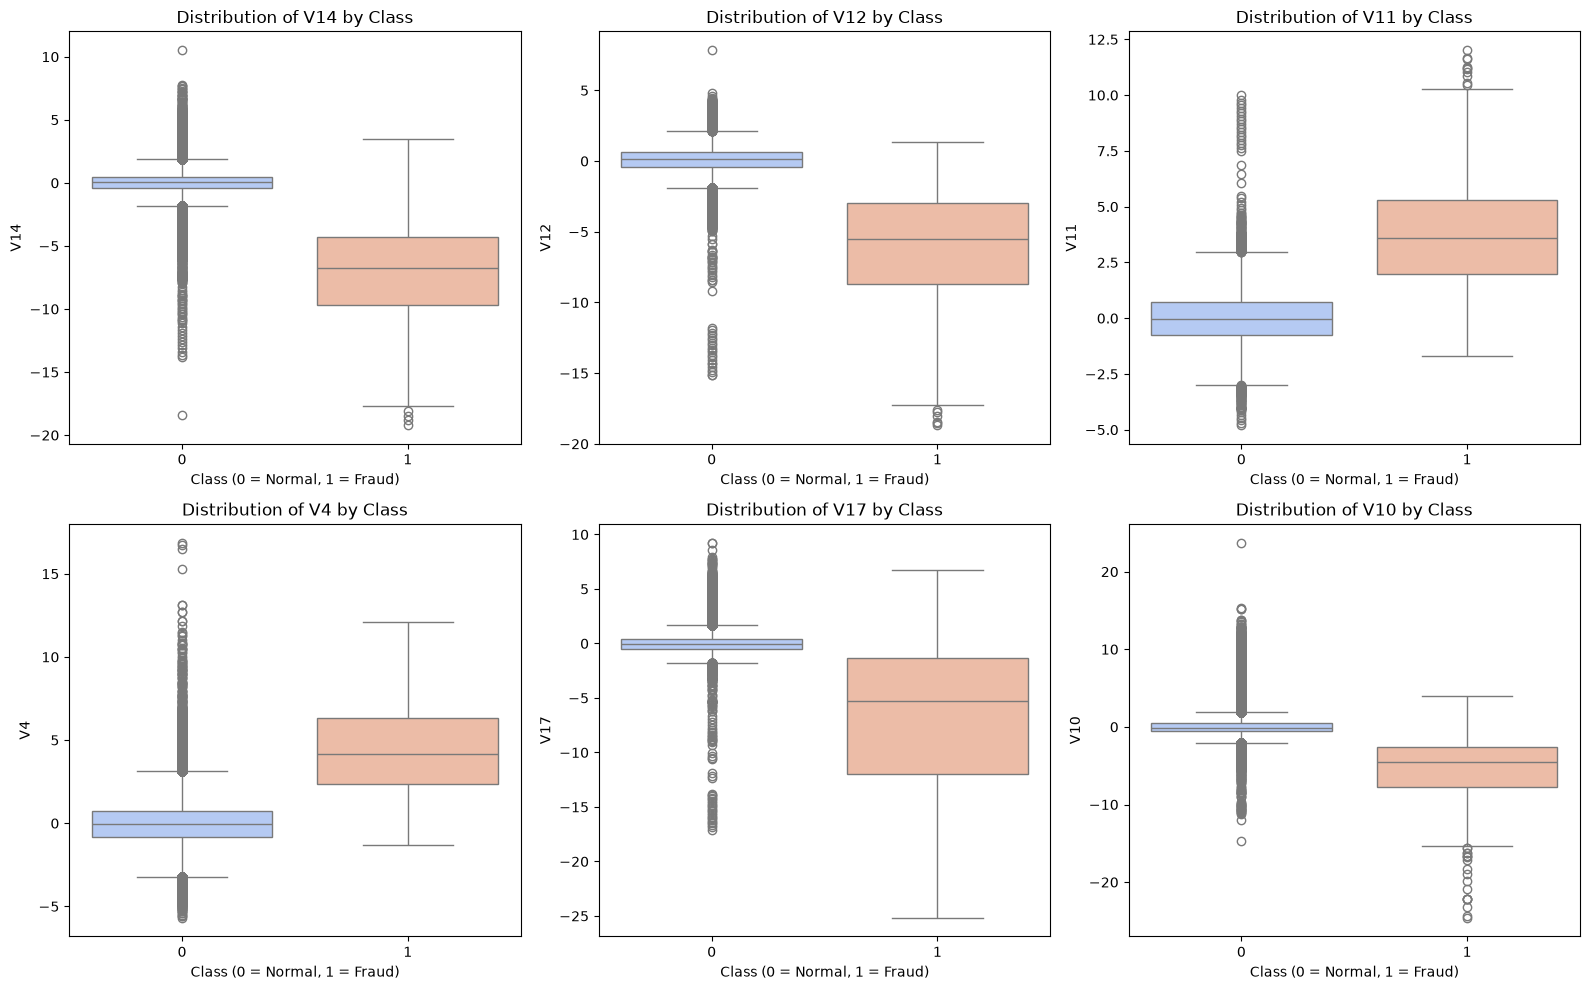

In [24]:
# Select the top signal features based on your correlation output
# Adjust these strings if your correlation ranking shows different top features
top_features = ['V14', 'V12', 'V11', 'V4' , 'V17' ,'V10']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    # Boxplot to clearly see the separation of distribution centers and IQRs
    sns.boxplot(x='Class', y=feature, data=df, ax=axes[i], hue='Class', palette='coolwarm', legend=False)
    axes[i].set_title(f'Distribution of {feature} by Class')
    axes[i].set_xlabel('Class (0 = Normal, 1 = Fraud)')
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()


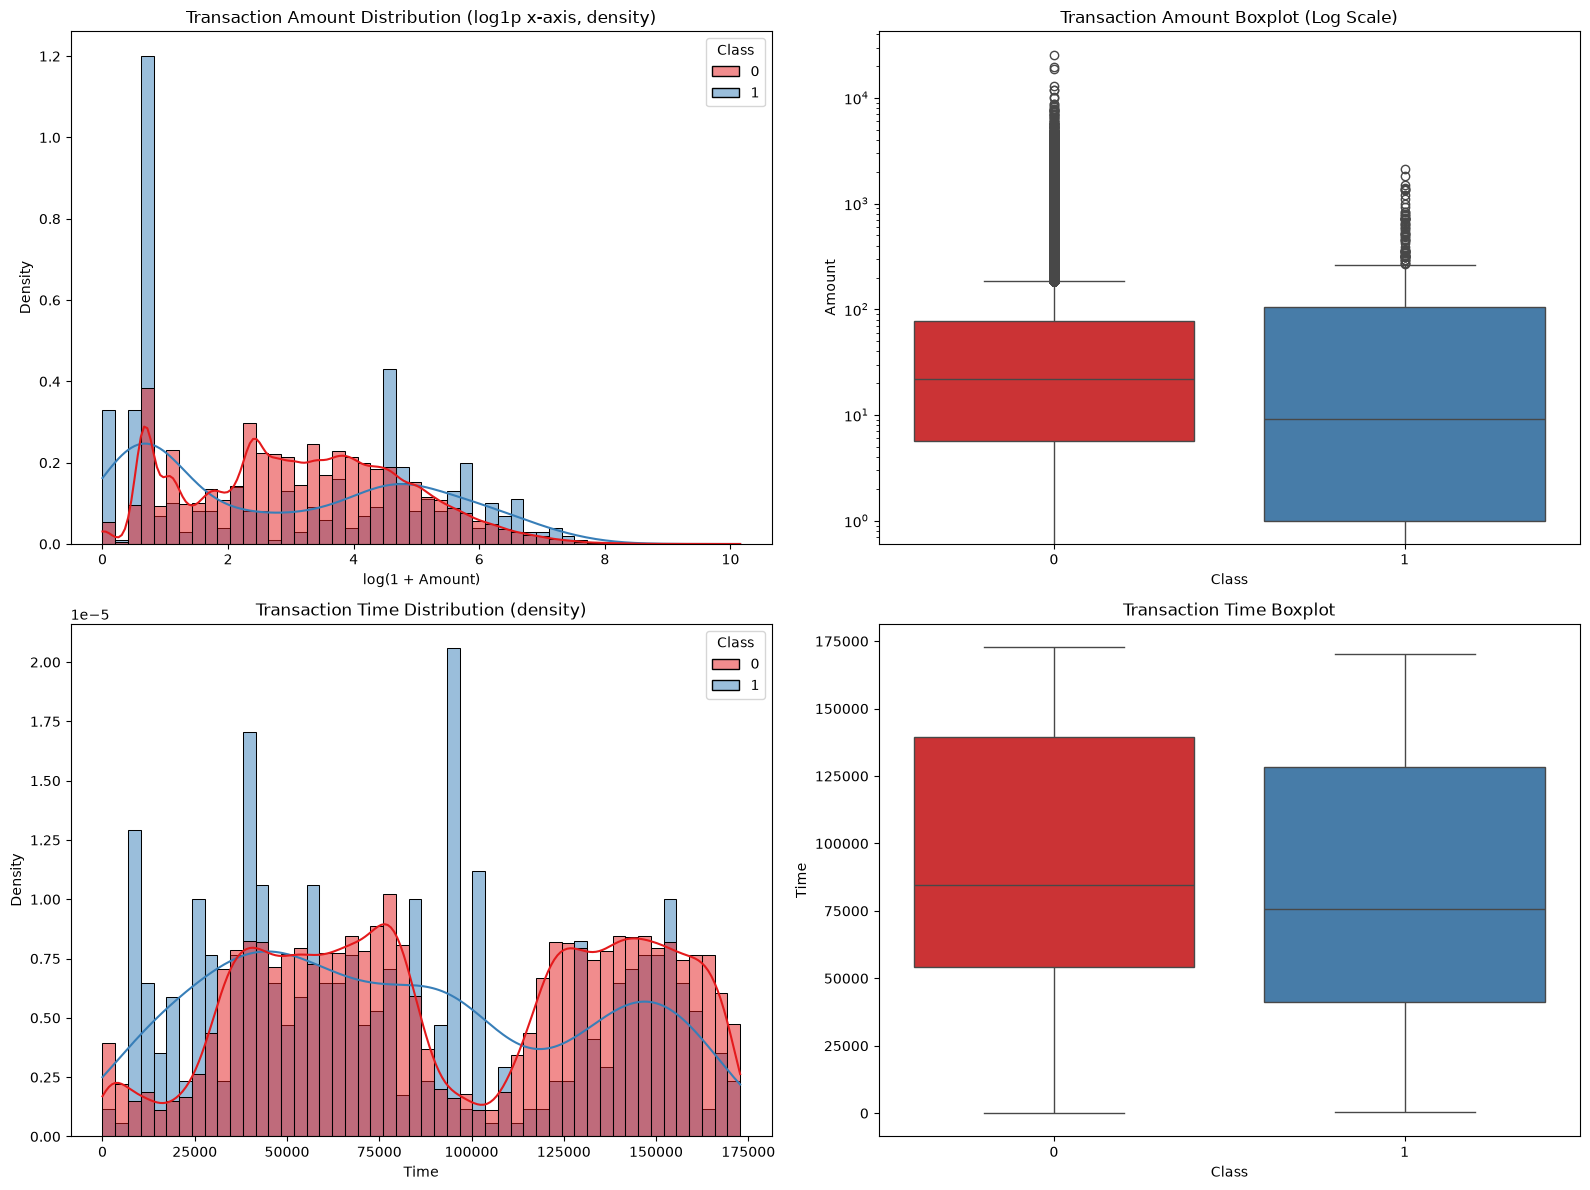

--- Amount Statistics by Class ---
             mean   25%    50%     75%       max
Class                                           
0       88.291022  5.65  22.00   77.05  25691.16
1      122.211321  1.00   9.25  105.89   2125.87


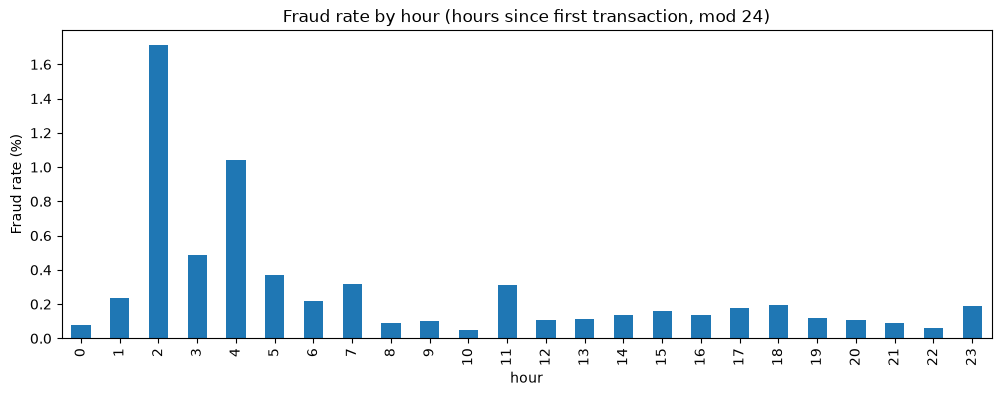

      total  fraud    rate_%
hour                        
0      7695      6  0.077973
1      4220     10  0.236967
2      3328     57  1.712740
3      3492     17  0.486827
4      2209     23  1.041195
5      2990     11  0.367893
6      4101      9  0.219459
7      7243     23  0.317548
8     10276      9  0.087583
9     15838     16  0.101023
10    16598      8  0.048199
11    16856     53  0.314428
12    15420     17  0.110246
13    15365     17  0.110641
14    16570     23  0.138805
15    16461     26  0.157949
16    16453     22  0.133714
17    16166     29  0.179389
18    17039     33  0.193673
19    15649     19  0.121414
20    16756     18  0.107424
21    17703     16  0.090380
22    15441      9  0.058286
23    10938     21  0.191991


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

df['log_amount'] = np.log1p(df['Amount'])   

# 1. Amount distribution: log-transformed x, density per class, no log y-axis
sns.histplot(data=df, x='log_amount', hue='Class', bins=50, kde=True,
             stat='density', common_norm=False,
             ax=axes[0, 0], palette='Set1')
axes[0, 0].set_title('Transaction Amount Distribution (log1p x-axis, density)')
axes[0, 0].set_xlabel('log(1 + Amount)')

# 2. Amount boxplot 
sns.boxplot(x='Class', y='Amount', data=df, ax=axes[0, 1],
            palette='Set1', hue='Class', legend=False)
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Transaction Amount Boxplot (Log Scale)')

# 3. Time distribution: density per class so fraud is visible
sns.histplot(data=df, x='Time', hue='Class', bins=50, kde=True,
             stat='density', common_norm=False,
             ax=axes[1, 0], palette='Set1')
axes[1, 0].set_title('Transaction Time Distribution (density)')

# 4. Time boxplot
sns.boxplot(x='Class', y='Time', data=df, ax=axes[1, 1],
            palette='Set1', hue='Class', legend=False)
axes[1, 1].set_title('Transaction Time Boxplot')

plt.tight_layout()
plt.show()

print("--- Amount Statistics by Class ---")
print(df.groupby('Class')['Amount'].describe()[['mean', '25%', '50%', '75%', 'max']])


df['hour'] = ((df['Time'] // 3600) % 24).astype(int)
hourly_fraud_rate = df.groupby('hour')['Class'].mean() * 100

hourly_fraud_rate.plot(kind='bar', figsize=(12, 4))
plt.ylabel('Fraud rate (%)')
plt.title('Fraud rate by hour (hours since first transaction, mod 24)')
plt.show()

hourly = df.groupby('hour')['Class'].agg(total='count', fraud='sum')
hourly['rate_%'] = hourly['fraud'] / hourly['total'] * 100
print(hourly)

### Key Insights & Modeling Strategy Implications

1. **Data Integrity:** 
   * The dataset has **zero missing values**, meaning we do not need to implement imputation strategies like mean/median filling. 
   * A small number of **duplicate rows** (Rows Found: 1081) exist, which should be removed to prevent data leakage between training and validation splits.
   * All features (`V1` through `V28`, `Time`, and `Amount`) are numerical, meaning no categorical encoding is necessary.

2. **The Impact of Extreme Class Imbalance:**
   * Because fraudulent transactions make up a tiny fraction of the data (~0.17%), **Accuracy is a useless metric.** A naive model that predicts "Normal" for every single transaction would achieve ~99.8% accuracy while missing 100% of the actual fraud.
   * To properly evaluate our future machine learning models, we must focus on **Precision** (minimizing false alarms for customers) and **Recall** (catching as many actual frauds as possible). 
   * The **Area Under the Precision-Recall Curve (AUPRC)** or **F1-Score** will be our primary benchmarks.
   * Resampling methods (SMOTE, undersampling, class_weight) only apply to supervised models. For the unsupervised **Isolation Forest** baseline, we’ll tune **contamination** instead, and use the labels only to evaluate the model. If we later add a supervised comparison model, resampling would apply to the training split only, never to validation or test data.

3. **V features:**
 several PCA components separate the classes strongly. V14, V12, V10, V16 and V17 are shifted negative for fraud; V11, V4 and V2 are shifted positive. Normal transactions cluster tightly around 0, while fraud lies far from that centre with a wide spread, which suggests an anomaly detector can work. However, normal transactions also have heavy tails that overlap the fraud range, so false positives are the main risk. Linear correlation with Class is modest (|r| ≤ 0.33) because of the extreme imbalance, so the boxplots are a better guide than the correlations. Any feature selection for modelling must be done on the training split only.

4. **Amount:**
 Fraud is bimodal: a large cluster of very small transactions (many at about $1) plus a mid/large tail, whereas normal transactions are concentrated in the $10–$150 range. Medians differ ($9.25 vs $22.00), but the distributions overlap heavily, so Amount is informative only in combination with other features.

5. **Time:**
 Fraud makes up a larger share of transactions during low-volume periods (hours 2 and 4 of the 24-hour cycle show about 10× the baseline fraud rate), but those estimates rest on small counts and Time is relative to the dataset start. Whether to use it as hour-of-day is a modelling-phase decision.

